# StrokeLens — Phân tích dữ liệu và phân loại nhãn đột quỵ
# StrokeLens — Data Analysis and Recorded-Stroke Classification

**Nguyễn Anh Khoa · Python · scikit-learn · FastAPI · React**

**VI:** Portfolio song ngữ từ đồ án cá nhân môn Machine Learning trong kinh tế. Tác giả trực tiếp thực hiện bài ML; phiên bản cải thiện phương pháp và phần ứng dụng được phát triển với hỗ trợ AI. Notebook độc lập với ứng dụng, có EDA, kiểm tra dữ liệu, CV/OOF và đánh giá holdout. Không sử dụng cho chẩn đoán, sàng lọc hoặc tư vấn sức khỏe.

**EN:** Bilingual portfolio based on individual ML coursework. The author completed the ML work; AI assisted methodological improvements and the application extension. The notebook runs independently of FastAPI/React. Educational use only: no diagnosis, screening or personal health advice.

## Tóm tắt / Executive summary

**VI:** 5.110 hồ sơ, 249 nhãn dương, 201 BMI thiếu. Chọn Logistic Regression bằng CV/OOF trên development. Holdout n=1022: AP 0.1715, ROC-AUC 0.8534, recall 82.0%, precision 14.7%. Đọc cùng dương tính giả và hạn chế hiệu chuẩn. Đây là chạy lại cùng thí nghiệm và cùng holdout, không phải kiểm định độc lập mới.

**EN:** 5,110 records, 249 recorded positives, 201 missing BMI values. Model selection uses development CV/OOF only. Final holdout n=1022: AP 0.1715, ROC-AUC 0.8534, recall 82.0%, precision 14.7%. Scores are not calibrated personal future-risk probabilities; this run reproduces the same fixed experiment, not external validation.

## 1. Mục tiêu và phương pháp
Phân tích tập trung vào hai câu hỏi: các đặc trưng quan sát có phân biệt được nhãn `stroke` hay không, và việc tăng khả năng nhận diện nhãn dương đánh đổi như thế nào với dương tính giả?

### Phạm vi và giả định
- Một dòng tương ứng một hồ sơ quan sát. `id` là định danh; `stroke` là nhãn nhị phân đã ghi nhận.
- Nguồn thu thập ban đầu không được công khai; thời gian và cơ chế chọn mẫu chưa xác định.
- Tuổi tính theo năm, bao gồm phần thập phân; BMI được diễn giải theo kg/m². Đơn vị glucose chưa được từ điển nguồn xác nhận nên giá trị CSV được giữ nguyên.
- Giữ danh mục `Other`, `Unknown`, các giá trị BMI thiếu và các giá trị cực trị. Thống kê điền thiếu chỉ được học trong phần huấn luyện.
- Các liên hệ quan sát và tầm quan trọng đặc trưng không được diễn giải thành quan hệ nhân quả.

### Thiết kế thí nghiệm
1. Kiểm tra nguồn, schema và khóa định danh; sắp theo `id`, chia phân tầng 80/20 với seed 42.
2. Giữ riêng holdout cuối; thực hiện cross-validation phân tầng 3 fold trên tập phát triển.
3. Fit imputer, scaler và classifier trong từng training fold; mã hóa one-hot theo danh mục đã khai báo.
4. So sánh hai cấu hình của mỗi họ mô hình. Sử dụng trọng số lớp khi được hỗ trợ; không nội suy danh mục bằng SMOTE trên mã số.
5. Với mỗi cấu hình, chọn ngưỡng tối đa precision với recall OOF ≥75%. OOF là dự đoán trên các hồ sơ không tham gia fit mô hình trong fold tương ứng.
6. Xét các cấu hình có precision ≥10%, xếp theo AP. Trong khoảng 0,01 AP so với tốt nhất, ưu tiên theo thứ tự LR → KNN → SVM → Decision Tree → Random Forest và thứ tự cấu hình đã khai báo.
7. Fit lại mô hình được chọn trên tập phát triển, sau đó đánh giá holdout. Holdout không tham gia chọn mô hình, ngưỡng hoặc hiệu chuẩn.

Các tiêu chí recall và precision trên là quy tắc lựa chọn của thí nghiệm, không phải tiêu chuẩn lâm sàng.

**English:** Methods: sorted-ID stratified 80/20 split; three-fold development CV; fold-fitted preprocessing; OOF model/threshold selection; fixed final holdout; no clinical or causal interpretation.

## 2. Thiết lập và tải dữ liệu / Setup and data access

**VI:** Xem `README.md`, `docs/DATA_ACCESS.md` và `requirements-notebook.txt`. Từ thư mục gốc StrokeLens, chạy `python scripts/download_data.py` sau khi đọc điều kiện nguồn. Notebook tìm CSV tại `data/raw/healthcare-dataset-stroke-data.csv`; không tự tải, cài package hoặc sinh dữ liệu giả.

**EN:** Review the publisher terms and follow `docs/DATA_ACCESS.md`. Place the original version-1 CSV in `data/raw/`; the notebook verifies its SHA-256. Select your Python environment in VS Code and run all cells in order. No private machine-specific environment is required.

Nguồn / Source: Fedesoriano, Kaggle, Stroke Prediction Dataset, version 1. Educational use only with author credit, as recorded in the existing provenance. Review current source terms before downloading.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
EXPECTED_SHA256 = '644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420'
DATA_FILENAME = 'healthcare-dataset-stroke-data.csv'
NUMERIC = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
CATEGORIES = {
    'gender': ['Female', 'Male', 'Other'],
    'ever_married': ['No', 'Yes'],
    'work_type': ['Govt_job', 'Never_worked', 'Private', 'Self-employed', 'children'],
    'Residence_type': ['Rural', 'Urban'],
    'smoking_status': ['Unknown', 'formerly smoked', 'never smoked', 'smokes'],
}
FEATURES = NUMERIC + list(CATEGORIES)
SOURCE_RANGES = {'age': (0.08, 82), 'avg_glucose_level': (55.12, 271.74), 'bmi': (10.3, 97.6)}
LABELS = {'age': 'Tuổi (năm)', 'avg_glucose_level': 'Glucose (đơn vị nguồn)',
          'bmi': 'BMI (kg/m²)', 'hypertension': 'Tăng huyết áp',
          'heart_disease': 'Bệnh tim', 'gender': 'Giới tính',
          'ever_married': 'Từng kết hôn', 'work_type': 'Công việc',
          'Residence_type': 'Nơi cư trú', 'smoking_status': 'Hút thuốc'}
COLORS = {'negative': '#6c91a8', 'positive': '#b87848', 'model': '#087f78'}
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 120,
                     'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 4)
ENVIRONMENT = {'python': platform.python_version(), 'pandas': pd.__version__,
               'numpy': np.__version__, 'sklearn': sklearn.__version__}
display(pd.Series(ENVIRONMENT, name='Phiên bản'))

python     3.14.8
pandas      3.0.6
numpy       2.5.4
sklearn     1.9.1
Name: Phiên bản, dtype: str

### 2.1. Đọc dữ liệu và kiểm tra checksum
SHA-256 được đối chiếu với CSV phiên bản đã xác minh. Nếu checksum khác, quá trình phân tích dừng để kiểm tra nguồn trước khi sử dụng dữ liệu.

**English:** Source checksum: exact original CSV bytes must match the documented SHA-256 before analysis.

In [2]:
import os
project_candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in project_candidates if (p / 'backend/train.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run from the StrokeLens root or notebooks/ folder.')
override = os.environ.get('STROKELENS_DATA_PATH')
DATA_PATH = Path(override) if override else PROJECT_ROOT / 'data/raw' / DATA_FILENAME
if not DATA_PATH.is_file():
    raise FileNotFoundError('Missing publisher CSV. Follow docs/DATA_ACCESS.md; raw data is not bundled.')
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if source_hash != EXPECTED_SHA256:
    raise ValueError('CSV checksum differs from source version 1. Review provenance before analysis.')
df_raw = pd.read_csv(DATA_PATH).sort_values('id').reset_index(drop=True)
print('Rows / columns:', df_raw.shape)
print('CSV SHA-256:', source_hash)
display(pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'missing_n': df_raw.isna().sum()}))

Rows / columns: (5110, 12)
CSV SHA-256: 644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420


,dtype,missing_n
id,int64,0
gender,str,0
age,float64,0
hypertension,int64,0
heart_disease,int64,0
ever_married,str,0
work_type,str,0
Residence_type,str,0
avg_glucose_level,float64,0
bmi,float64,201


### 2.2. Kiểm tra cấu trúc và chất lượng dữ liệu
Kiểm tra tên cột, kiểu dữ liệu, danh mục, giá trị không hữu hạn, khóa `id` trùng và bản ghi trùng hoàn toàn. Chỉ BMI được phép thiếu theo cấu trúc nguồn. Khoảng giá trị kiểm tra phản ánh dữ liệu quan sát của phiên bản 1, không phải ngưỡng đánh giá sức khỏe.

**English:** Data validation: verify schema, missingness, duplicates, categories and observed numeric support. These ranges are source constraints, not clinical cutoffs.

In [3]:
def validate_source(frame):
    expected_columns = set(FEATURES + ['id', 'stroke'])
    if set(frame.columns) != expected_columns:
        raise ValueError(f'Sai schema: cần {sorted(expected_columns)}')
    if frame.empty or frame['id'].isna().any() or frame['id'].duplicated().any():
        raise ValueError('Dữ liệu rỗng hoặc khóa id thiếu/trùng.')
    for column in NUMERIC + ['stroke']:
        if not pd.api.types.is_numeric_dtype(frame[column]):
            raise ValueError(f'{column} phải là numeric.')
        if column != 'bmi' and frame[column].isna().any():
            raise ValueError(f'{column} thiếu ngoài contract.')
        if not np.isfinite(frame[column].dropna()).all():
            raise ValueError(f'{column} có giá trị không hữu hạn.')
    for column in ['hypertension', 'heart_disease', 'stroke']:
        if not frame[column].isin([0, 1]).all():
            raise ValueError(f'{column} phải là 0/1.')
    if frame['stroke'].nunique() != 2:
        raise ValueError('Cần cả hai lớp để đánh giá.')
    for column, values in CATEGORIES.items():
        if not frame[column].isin(values).all():
            raise ValueError(f'{column} có category lạ hoặc thiếu.')
    for column, (low, high) in SOURCE_RANGES.items():
        if not frame[column].dropna().between(low, high).all():
            raise ValueError(f'{column} ngoài source range [{low}, {high}].')

validate_source(df_raw)
quality = pd.DataFrame({'dtype': df_raw.dtypes.astype(str),
                        'missing_n': df_raw.isna().sum(),
                        'missing_pct': df_raw.isna().mean() * 100,
                        'distinct_n': df_raw.nunique(dropna=True)})
display(quality)
print('Full-row duplicates:', df_raw.duplicated().sum())
print('Duplicate id:', df_raw['id'].duplicated().sum())
display(df_raw[['age', 'avg_glucose_level', 'bmi']].describe().T)

,dtype,missing_n,missing_pct,distinct_n
id,int64,0,0.0000,5110
gender,str,0,0.0000,3
age,float64,0,0.0000,104
hypertension,int64,0,0.0000,2
heart_disease,int64,0,0.0000,2
ever_married,str,0,0.0000,2
work_type,str,0,0.0000,5
Residence_type,str,0,0.0000,2
avg_glucose_level,float64,0,0.0000,3979
bmi,float64,201,3.9335,418


Full-row duplicates: 0
Duplicate id: 0


,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.2266,22.6126,0.08,25.000,45.000,61.00,82.00
avg_glucose_level,5110.0,106.1477,45.2836,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.8932,7.8541,10.30,23.500,28.100,33.10,97.60


### 2.3. Đối chiếu sai lệch số liệu
Notebook tham chiếu ghi nhận tuổi tối đa 188 và glucose trung bình khoảng 9.622,81. Để kiểm tra giả thuyết mất dấu thập phân, giá trị numeric trong CSV được chuyển thành chuỗi chuẩn hóa rồi loại dấu chấm trong một bản mô phỏng riêng.

Phép mô phỏng tái tạo các thống kê bất thường nhưng chưa xác định được chính xác bước chuyển đổi Excel gây lỗi vì file Excel không có trong nguồn cung cấp. Phân tích sử dụng lại CSV gốc; không chia toàn bộ cột cho 100 vì phép chia đó sẽ làm sai các giá trị nguyên hoặc chỉ có một chữ số thập phân.

**English:** Import integrity: decimal-removal reconstruction reproduces the old anomalies, but the exact spreadsheet operation is unknown. Reload the authoritative CSV; do not divide the entire column by 100.

In [4]:
def reproduce_decimal_loss(series):
    return (series.astype(str).str.rstrip('0').str.rstrip('.')
            .str.replace('.', '', regex=False).astype(float))

age_corrupted_example = reproduce_decimal_loss(df_raw['age'])
glucose_corrupted_example = reproduce_decimal_loss(df_raw['avg_glucose_level'])
decimal_audit = pd.DataFrame({
    'Chỉ số': ['Tuổi tối đa', 'Tuổi trung bình', 'Glucose trung bình'],
    'CSV gốc': [df_raw.age.max(), df_raw.age.mean(), df_raw.avg_glucose_level.mean()],
    'Mô phỏng mất dấu': [age_corrupted_example.max(), age_corrupted_example.mean(),
                        glucose_corrupted_example.mean()],
    'Notebook cũ — historical claim': [188, 45.3154598826, 9622.8091976517],
})
display(decimal_audit)
assert age_corrupted_example.max() == 188
assert np.isclose(glucose_corrupted_example.mean(), 9622.8091976517)
print('Không thay đổi df_raw; mô hình chỉ sử dụng CSV gốc.')

,Chỉ số,CSV gốc,Mô phỏng mất dấu,Notebook cũ — historical claim
0,Tuổi tối đa,82.0000,188.0000,188.0000
1,Tuổi trung bình,43.2266,45.3155,45.3155
2,Glucose trung bình,106.1477,9622.8092,9622.8092


Không thay đổi df_raw; mô hình chỉ sử dụng CSV gốc.


## 3. Phân tích khám phá dữ liệu
Tỷ lệ nhãn dương được định nghĩa là số hồ sơ `stroke=1` chia cho tổng số hồ sơ trong nhóm, đơn vị %. BMI thiếu không bị loại khỏi mẫu số của tỷ lệ nhãn. Tỷ lệ này mô tả tập dữ liệu, không phải tỷ lệ mắc mới trong quần thể.

EDA theo nhãn chỉ sử dụng tập phát triển để tránh xem kết quả holdout trước khi lựa chọn mô hình. Kiểm tra dữ liệu nguồn xác nhận cấu trúc; thống kê toàn bộ dữ liệu không được dùng để fit preprocessing. Dữ liệu không có biến thời gian nên không thực hiện phân tích xu hướng hoặc dự báo chuỗi thời gian.

**English:** Exploration: describe all observed records and report denominators. Exploration uses the development subset; source-quality counts also describe the full CSV. Do not change the locked model or holdout policy from exploratory findings.

In [5]:
development_index, holdout_index = train_test_split(
    np.arange(len(df_raw)), test_size=0.20, random_state=SEED,
    stratify=df_raw['stroke'],
)
development = df_raw.iloc[development_index].copy()
assert set(development_index).isdisjoint(holdout_index)
assert len(development_index) + len(holdout_index) == len(df_raw)
split_table = pd.DataFrame({
    'Tập': ['Development — EDA/CV/fit', 'Holdout — khóa trước lựa chọn'],
    'Số dòng': [len(development_index), len(holdout_index)],
})
display(split_table)
print('Development positives:', development.stroke.sum())

,Tập,Số dòng
0,Development — EDA/CV/fit,4088
1,Holdout — khóa trước lựa chọn,1022


Development positives: 199


### 3.1. Phân phối nhãn và baseline
Độ mất cân bằng lớp được kiểm tra bằng số lượng và tỷ lệ từng nhãn. Baseline dự đoán lớp đa số có thể đạt accuracy cao nhưng recall bằng 0. AP của một score không phân biệt được hai lớp bằng tỷ lệ nhãn dương trong tập đánh giá.

**English:** Target imbalance: the recorded positive label is rare; majority accuracy alone is an inadequate measure of positive detection.

,Số dòng,Tỷ lệ (%)
Không ghi nhận đột quỵ,3889,95.1321
Ghi nhận đột quỵ,199,4.8679


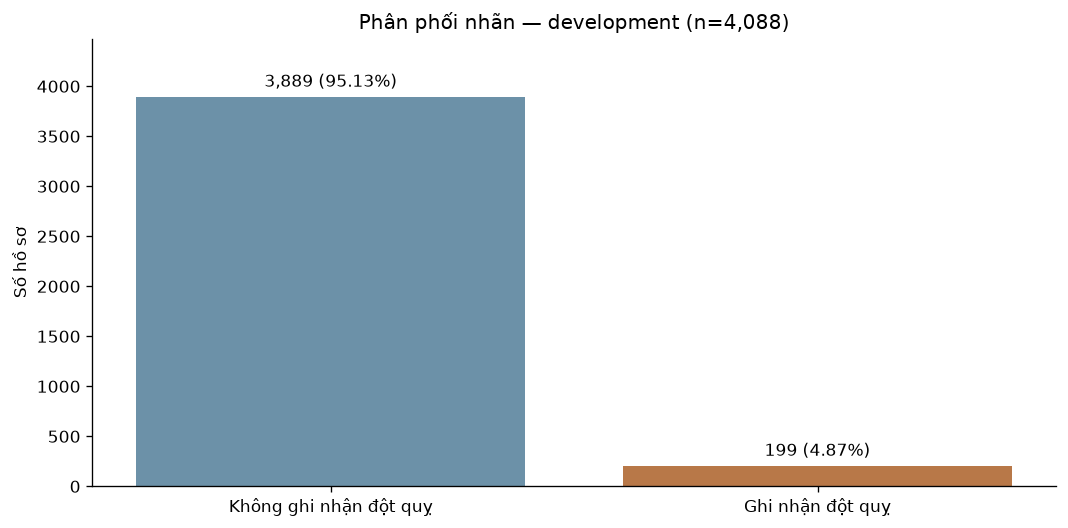

In [6]:
class_counts = development['stroke'].value_counts().reindex([0, 1], fill_value=0)
class_table = pd.DataFrame({'Số dòng': class_counts, 'Tỷ lệ (%)': class_counts / len(development) * 100})
class_table.index = ['Không ghi nhận đột quỵ', 'Ghi nhận đột quỵ']
display(class_table)
fig, ax = plt.subplots()
bars = ax.bar(class_table.index, class_table['Số dòng'],
              color=[COLORS['negative'], COLORS['positive']])
ax.bar_label(bars, labels=[f'{n:,} ({n / len(development):.2%})' for n in class_counts], padding=4)
ax.set(title=f'Phân phối nhãn — development (n={len(development):,})', ylabel='Số hồ sơ')
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout(); plt.show()

### 3.2. Phân phối tuổi, glucose và BMI
Histogram sử dụng các giá trị quan sát, không điền BMI thiếu để vẽ phân phối. Mỗi biểu đồ ghi số hồ sơ có dữ liệu và số giá trị thiếu; giá trị cực trị được giữ lại.

**English:** Numeric distributions: retain extreme observations and missing BMI; do not silently impute or remove rows for EDA.

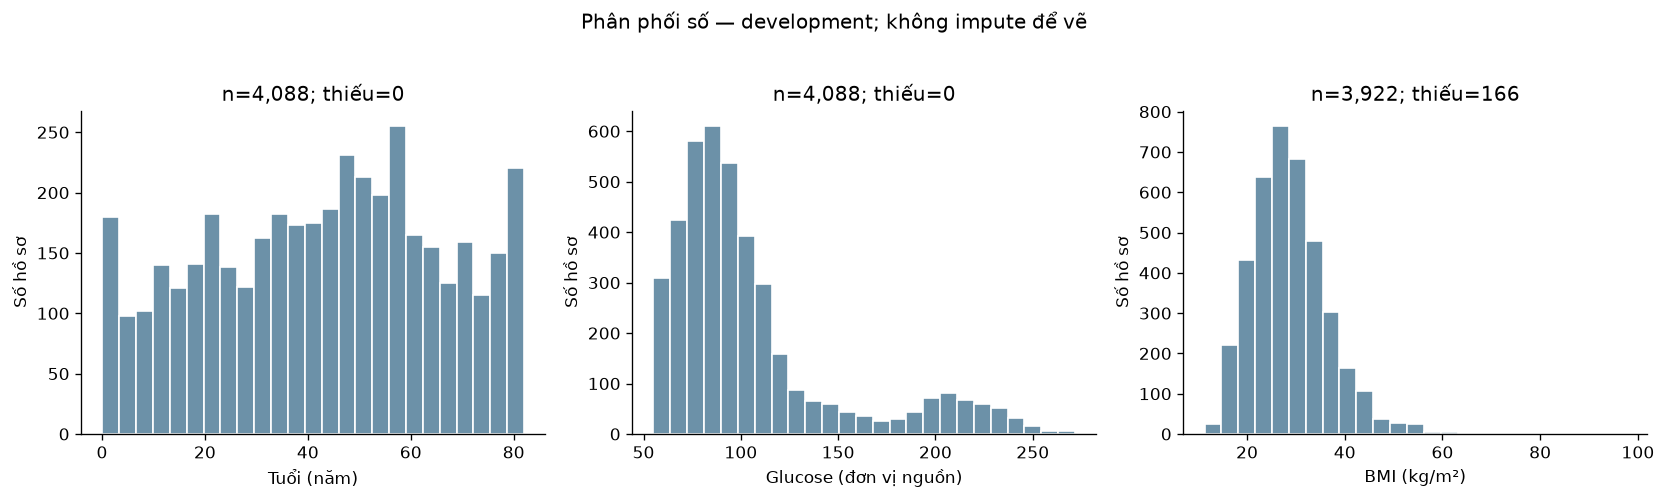

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    observed = development[column].dropna()
    ax.hist(observed, bins=25, color=COLORS['negative'], edgecolor='white')
    ax.set(title=f'n={len(observed):,}; thiếu={development[column].isna().sum()}',
           xlabel=LABELS[column], ylabel='Số hồ sơ')
fig.suptitle('Phân phối số — development; không impute để vẽ', y=1.03)
plt.tight_layout(); plt.show()

### 3.3. Tỷ lệ BMI thiếu theo nhãn
So sánh số lượng và tỷ lệ BMI thiếu giữa hai nhãn để đánh giá khác biệt về missingness. Kết quả không đủ để xác định cơ chế MCAR/MAR/MNAR. Điền median là lựa chọn xử lý đơn giản và không loại bỏ được thiên lệch chọn mẫu.

**English:** Missing BMI: report missing counts, denominators and rates by recorded label; missingness is not evidence of a medical cause.

,denominator,missing_bmi,missing_pct
stroke,,,
0,3889,130,3.3428
1,199,36,18.0905


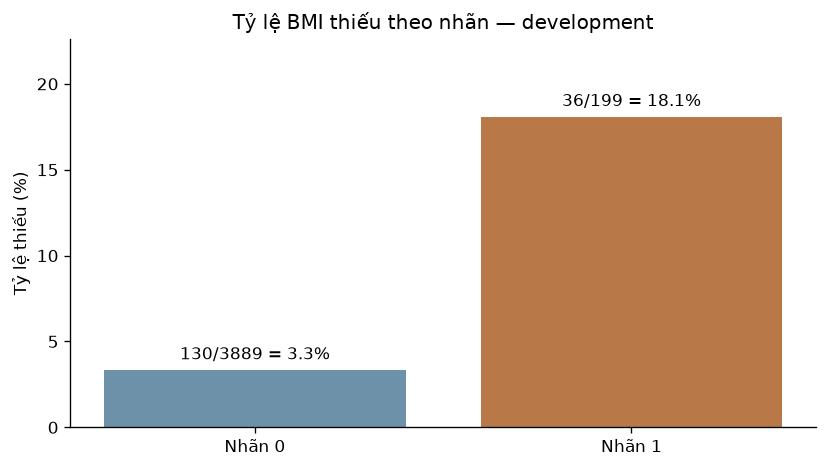

In [8]:
missing_by_label = development.groupby('stroke').agg(
    denominator=('stroke', 'size'), missing_bmi=('bmi', lambda s: s.isna().sum()))
missing_by_label['missing_pct'] = missing_by_label['missing_bmi'] / missing_by_label['denominator'] * 100
display(missing_by_label)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Nhãn 0', 'Nhãn 1'], missing_by_label['missing_pct'],
              color=[COLORS['negative'], COLORS['positive']])
ax.bar_label(bars, labels=[f'{r.missing_bmi}/{r.denominator} = {r.missing_pct:.1f}%'
                         for r in missing_by_label.itertuples()], padding=4)
ax.set(title='Tỷ lệ BMI thiếu theo nhãn — development', ylabel='Tỷ lệ thiếu (%)')
ax.set_ylim(0, max(missing_by_label['missing_pct'].max() * 1.25, 5))
plt.tight_layout(); plt.show()

### 3.4. Tỷ lệ nhãn theo nhóm tuổi
Các nhóm tuổi được xác định trước. Mỗi nhóm được báo cáo số hồ sơ, số nhãn dương, tỷ lệ và khoảng Wilson 95%. Khoảng này mô tả bất định của tỷ lệ trong mẫu, không hiệu chỉnh thiên lệch chọn mẫu.

**English:** Age groups: compare recorded-positive proportions with group sizes and Wilson intervals; these are unadjusted associations.

,n,positives,rate,ci_low,ci_high
age,,,,,
0–<20,782,2,0.0026,0.0007,0.0093
20–<40,959,5,0.0052,0.0022,0.0121
40–<60,1258,47,0.0374,0.0282,0.0493
60–82,1089,145,0.1331,0.1143,0.1546


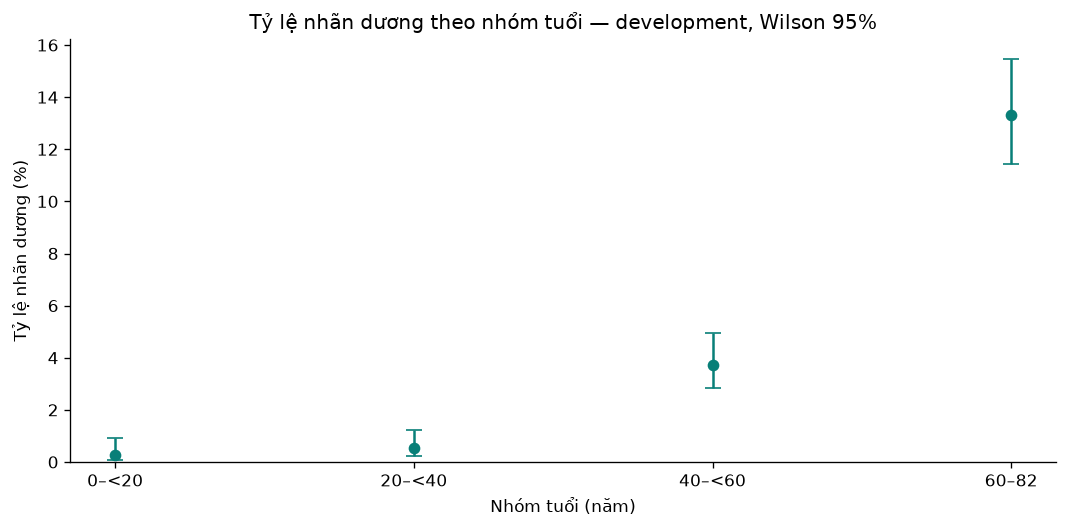

In [9]:
def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half = z * np.sqrt(proportion * (1-proportion)/total + z**2/(4*total**2)) / denominator
    return center - half, center + half

age_group = pd.cut(development.age, [0, 20, 40, 60, 83], right=False,
                   labels=['0–<20', '20–<40', '40–<60', '60–82'])
age_summary = development.groupby(age_group, observed=False)['stroke'].agg(n='size', positives='sum')
age_summary['rate'] = age_summary.positives / age_summary.n
age_summary[['ci_low', 'ci_high']] = pd.DataFrame(
    [wilson_interval(int(row.positives), int(row.n)) for row in age_summary.itertuples()],
    index=age_summary.index)
display(age_summary)
fig, ax = plt.subplots()
ax.errorbar(age_summary.index.astype(str), age_summary.rate * 100,
            yerr=np.vstack([(age_summary.rate-age_summary.ci_low)*100,
                            (age_summary.ci_high-age_summary.rate)*100]),
            fmt='o', capsize=5, color=COLORS['model'])
ax.set(title='Tỷ lệ nhãn dương theo nhóm tuổi — development, Wilson 95%',
       xlabel='Nhóm tuổi (năm)', ylabel='Tỷ lệ nhãn dương (%)')
ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

Chênh lệch tỷ lệ giữa các nhóm tuổi chỉ phản ánh mối liên hệ trong mẫu và chưa kiểm soát yếu tố nhiễu. Tỷ lệ cần được đọc cùng mẫu số và khoảng bất định, không được diễn giải thành tác động nhân quả của tuổi.

**English:** Age-group differences are unadjusted descriptive associations, not the causal effect of age.

### 3.5. Phân phối các danh mục
Các biến nominal không có thứ tự được giữ dưới dạng danh mục. `Unknown` của hút thuốc biểu thị thông tin chưa có, khác với `never smoked`. `Other` chỉ có một hồ sơ trong nguồn nên chưa đủ để đánh giá hiệu năng mô hình riêng cho nhóm này.

**English:** Categorical distributions: retain Other and Unknown; report counts and denominators, especially for rare categories.

In [10]:
category_tables = []
for column in CATEGORIES:
    table = development.groupby(column, observed=True)['stroke'].agg(n='size', positives='sum')
    table['positive_pct'] = table.positives / table.n * 100
    table['feature'] = column
    category_tables.append(table.reset_index().rename(columns={column: 'category'}))
display(pd.concat(category_tables, ignore_index=True)[['feature', 'category', 'n', 'positives', 'positive_pct']])

,feature,category,n,positives,positive_pct
0,gender,Female,2377,108,4.5435
1,gender,Male,1710,91,5.3216
2,gender,Other,1,0,0.0000
3,ever_married,No,1427,22,1.5417
4,ever_married,Yes,2661,177,6.6516
5,work_type,Govt_job,525,29,5.5238
6,work_type,Never_worked,19,0,0.0000
7,work_type,Private,2344,115,4.9061
8,work_type,Self-employed,644,53,8.2298
9,work_type,children,556,2,0.3597


### 3.6. Tương quan giữa các biến số
Pearson đo mối liên hệ tuyến tính; khi một biến là nhãn nhị phân, hệ số tương ứng với tương quan point-biserial. Tính toán sử dụng các cặp quan sát đủ dữ liệu nên BMI có mẫu số khác. Số cặp quan sát được báo cáo cùng ma trận tương quan.

**English:** Numeric correlation: descriptive relationships only, without causal or intervention claims.

,age,avg_glucose_level,bmi,stroke
N pairwise-complete,,,,
age,4088,4088,3922,4088
avg_glucose_level,4088,4088,3922,4088
bmi,3922,3922,3922,3922
stroke,4088,4088,3922,4088


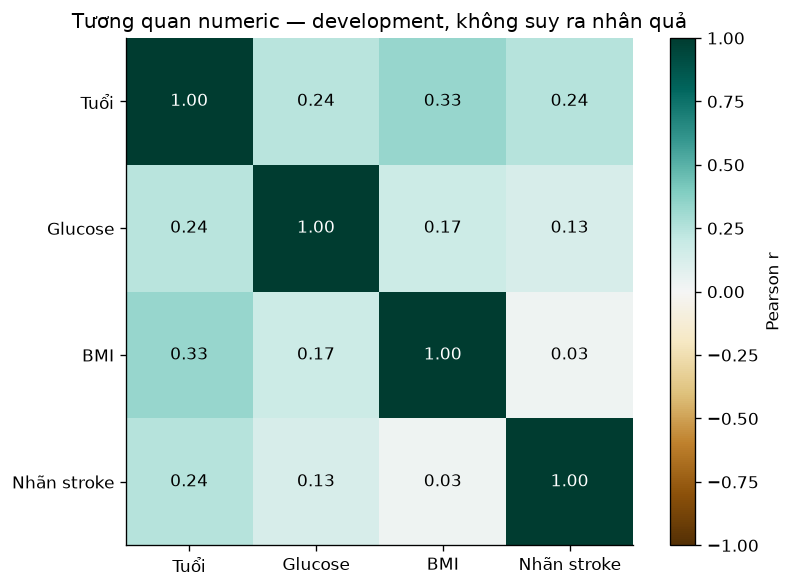

In [11]:
corr_columns = ['age', 'avg_glucose_level', 'bmi', 'stroke']
correlation = development[corr_columns].corr()
pair_counts = development[corr_columns].notna().astype(int).T @ development[corr_columns].notna().astype(int)
display(pair_counts.rename_axis('N pairwise-complete'))
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(correlation, cmap='BrBG', vmin=-1, vmax=1)
ax.set_xticks(range(4), ['Tuổi', 'Glucose', 'BMI', 'Nhãn stroke'])
ax.set_yticks(range(4), ['Tuổi', 'Glucose', 'BMI', 'Nhãn stroke'])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{correlation.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(correlation.iloc[i,j]) > .65 else 'black')
fig.colorbar(image, ax=ax, label='Pearson r')
ax.set_title('Tương quan numeric — development, không suy ra nhân quả')
plt.tight_layout(); plt.show()

## 4. Huấn luyện và lựa chọn mô hình
### 4.1. Chỉ số đánh giá và pipeline
- Recall = TP/(TP+FN); precision = TP/(TP+FP); F1 là trung bình điều hòa của precision và recall.
- AP (average precision) tổng hợp precision–recall theo thứ hạng, khác diện tích PR tính bằng phương pháp hình thang.
- ROC-AUC đánh giá khả năng xếp hạng trên hai lớp; accuracy = (TP+TN)/N. Các chỉ số này được đọc cùng AP, recall và precision do dữ liệu mất cân bằng.
- Brier = mean((score − y)²); giá trị thấp hơn tốt hơn và cần được so với baseline. Trọng số lớp có thể làm điểm số lệch hiệu chuẩn.

Pipeline gồm median imputation và StandardScaler cho numeric, one-hot cho nominal, sau đó là classifier. Scaling không cần thiết với tree nhưng được giữ để thống nhất preprocessing. `id` và `stroke` không là predictors. Vocabulary có `Other`; `handle_unknown='ignore'` hỗ trợ biến đổi dữ liệu, trong khi hàm mô phỏng kiểm tra danh mục đầu vào.

**English:** Training: preserve the stratified development/holdout split and fold-fitted preprocessing; no holdout-driven tuning.

In [12]:
def make_pipeline(estimator):
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ])
    encoder = OneHotEncoder(categories=list(CATEGORIES.values()),
                            handle_unknown='ignore', sparse_output=False)
    preprocess = ColumnTransformer([
        ('numeric', numeric_pipeline, NUMERIC),
        ('category', encoder, list(CATEGORIES)),
    ])
    return Pipeline([('preprocess', preprocess), ('model', estimator)])

def candidate_models():
    for c in [0.1, 1.0]:
        yield 'Logistic Regression', {'C': c}, LogisticRegression(
            C=c, class_weight='balanced', max_iter=2000, random_state=SEED)
    for k in [15, 35]:
        yield 'KNN', {'n_neighbors': k}, KNeighborsClassifier(n_neighbors=k)
    for c in [0.1, 1.0]:
        yield 'RBF SVM', {'C': c}, SVC(C=c, kernel='rbf', gamma='scale',
            class_weight='balanced', probability=True, random_state=SEED)
    for depth in [3, 5]:
        yield 'Decision Tree', {'max_depth': depth}, DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=30, class_weight='balanced', random_state=SEED)
    for depth in [5, 10]:
        yield 'Random Forest', {'max_depth': depth}, RandomForestClassifier(
            max_depth=depth, n_estimators=150, min_samples_leaf=10,
            class_weight='balanced_subsample', random_state=SEED, n_jobs=1)

def select_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    eligible = np.flatnonzero(recall[:-1] >= 0.75)
    index = max(eligible, key=lambda i: (precision[i], thresholds[i]))
    return float(thresholds[index])

def evaluate_scores(labels, scores, threshold):
    predictions = scores >= threshold
    return {
        'ap': float(average_precision_score(labels, scores)),
        'recall': float(recall_score(labels, predictions, zero_division=0)),
        'precision': float(precision_score(labels, predictions, zero_division=0)),
        'f1': float(f1_score(labels, predictions, zero_division=0)),
        'roc_auc': float(roc_auc_score(labels, scores)),
        'accuracy': float(accuracy_score(labels, predictions)),
        'brier': float(brier_score_loss(labels, scores)),
        'confusion': confusion_matrix(labels, predictions, labels=[0, 1]).tolist(),
    }

X_dev = development[FEATURES]
y_dev = development['stroke']
folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_dev, y_dev))
print(make_pipeline(LogisticRegression()).steps)

[('preprocess', ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'hypertension', 'heart_disease',
                                  'avg_glucose_level', 'bmi']),
                                ('category',
                                 OneHotEncoder(categories=[['Female', 'Male',
                                                            'Other'],
                                                           ['No', 'Yes'],
                                                           ['Govt_job',
                                                            'Never_worked',
                                                            'Private',
                                                            'Self-employed',
              

### 4.2. So sánh năm họ mô hình bằng OOF
Mỗi cấu hình được fit trong training fold và dự đoán validation fold. Toàn bộ preprocessing nằm trong pipeline, không fit scaler trước cross-validation. Precision và recall được đánh giá đồng thời để phản ánh đánh đổi khi thay đổi ngưỡng.

SVM sử dụng `probability=True` với fitting probability nội bộ trên dữ liệu của outer training fold. Tham số này có deprecation warning trong scikit-learn 1.9; khi nâng phiên bản loại bỏ tham số, cần thay thế bằng calibrated SVM phù hợp và kiểm chứng lại thí nghiệm.

**English:** OOF comparison: evaluate ten configurations across five families using development data only.

In [13]:
trials, unfitted_pipelines, oof_predictions = [], [], []
started = time.perf_counter()
for family, settings, estimator in candidate_models():
    pipeline = make_pipeline(estimator)
    scores = cross_val_predict(pipeline, X_dev, y_dev, cv=folds,
                               method='predict_proba', n_jobs=1)[:, 1]
    threshold = select_threshold(y_dev, scores)
    trial = {'family': family, 'settings': settings, 'threshold': threshold,
             **evaluate_scores(y_dev, scores, threshold)}
    trial['fold_ap'] = [float(average_precision_score(y_dev.iloc[val], scores[val]))
                        for _, val in folds]
    trials.append(trial)
    unfitted_pipelines.append(pipeline)
    oof_predictions.append(scores)
    print(f'{family:20s} {settings} | OOF AP={trial["ap"]:.4f}')
comparison = pd.DataFrame(trials)
display(comparison[['family', 'settings', 'threshold', 'ap', 'recall', 'precision',
                    'f1', 'roc_auc', 'brier']].round(4))
print(f'Thời gian CV quan sát: {time.perf_counter() - started:.1f} giây')

Logistic Regression  {'C': 0.1} | OOF AP=0.1793


Logistic Regression  {'C': 1.0} | OOF AP=0.1768


KNN                  {'n_neighbors': 15} | OOF AP=0.1057


KNN                  {'n_neighbors': 35} | OOF AP=0.1291


<notebook-environment>\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


...

RBF SVM              {'C': 1.0} | OOF AP=0.1318
Decision Tree        {'max_depth': 3} | OOF AP=0.1465
Decision Tree        {'max_depth': 5} | OOF AP=0.1496


Random Forest        {'max_depth': 5} | OOF AP=0.1636


Random Forest        {'max_depth': 10} | OOF AP=0.1627


,family,settings,threshold,ap,recall,precision,f1,roc_auc,brier
0,Logistic Regression,{'C': 0.1},0.5366,0.1793,0.7940,0.1456,0.2461,0.8309,0.1724
1,Logistic Regression,{'C': 1.0},0.5374,0.1768,0.7739,0.1434,0.2419,0.8301,0.1728
2,KNN,{'n_neighbors': 15},0.0000,0.1057,1.0000,0.0487,0.0928,0.7148,0.0457
3,KNN,{'n_neighbors': 35},0.0571,0.1291,0.8141,0.1023,0.1818,0.7727,0.0441
4,RBF SVM,{'C': 0.1},0.0764,0.1525,0.7538,0.1472,0.2463,0.8176,0.0431
5,RBF SVM,{'C': 1.0},0.0492,0.1318,0.7538,0.1080,0.1889,0.7786,0.0443
6,Decision Tree,{'max_depth': 3},0.6154,0.1465,0.7889,0.1206,0.2092,0.7870,0.1847
7,Decision Tree,{'max_depth': 5},0.5184,0.1496,0.7538,0.1125,0.1958,0.7749,0.1692
8,Random Forest,{'max_depth': 5},0.5275,0.1636,0.7538,0.1515,0.2523,0.8260,0.1448
9,Random Forest,{'max_depth': 10},0.3934,0.1627,0.7538,0.1521,0.2532,0.8268,0.0992


Thời gian CV quan sát: 8.6 giây


### 4.3. Lựa chọn mô hình
Áp dụng quy tắc recall, precision, AP và thứ tự ưu tiên đã khai báo ở phần phương pháp. OOF tham gia lựa chọn cấu hình và ngưỡng nên có thể cho ước lượng lạc quan; kết quả holdout được báo cáo riêng.

**English:** Selection: use the predeclared OOF recall/precision eligibility and AP ranking with a simplicity preference.

In [14]:
eligible_indices = [i for i, row in enumerate(trials)
                    if row['recall'] >= .75 and row['precision'] >= .10]
constraint_met = bool(eligible_indices)
if not constraint_met:
    print('Không model nào đạt constraint; fallback AP đã khai báo, không khẳng định đạt yêu cầu.')
eligible_indices = eligible_indices or list(range(len(trials)))
best_ap = max(trials[i]['ap'] for i in eligible_indices)
winner_index = min(i for i in eligible_indices if trials[i]['ap'] >= best_ap - .01)
selected = trials[winner_index]
selected_threshold = selected['threshold']
selected_oof = oof_predictions[winner_index]
display(pd.Series({k:v for k,v in selected.items() if k not in ['confusion', 'fold_ap']}))

family       Logistic Regression
settings              {'C': 0.1}
threshold                 0.5366
ap                        0.1793
recall                     0.794
precision                 0.1456
f1                        0.2461
roc_auc                   0.8309
accuracy                  0.7632
brier                     0.1724
dtype: object

### 4.4. Precision–recall và đánh đổi ngưỡng
Đường PR mô tả khả năng xếp hạng từ dự đoán OOF. Biểu đồ theo ngưỡng thể hiện thay đổi của precision và recall; ngưỡng được chọn được giữ cố định cho đánh giá holdout.

**English:** Threshold trade-off: precision and recall change together; do not optimize thresholds by inspecting holdout outcomes.

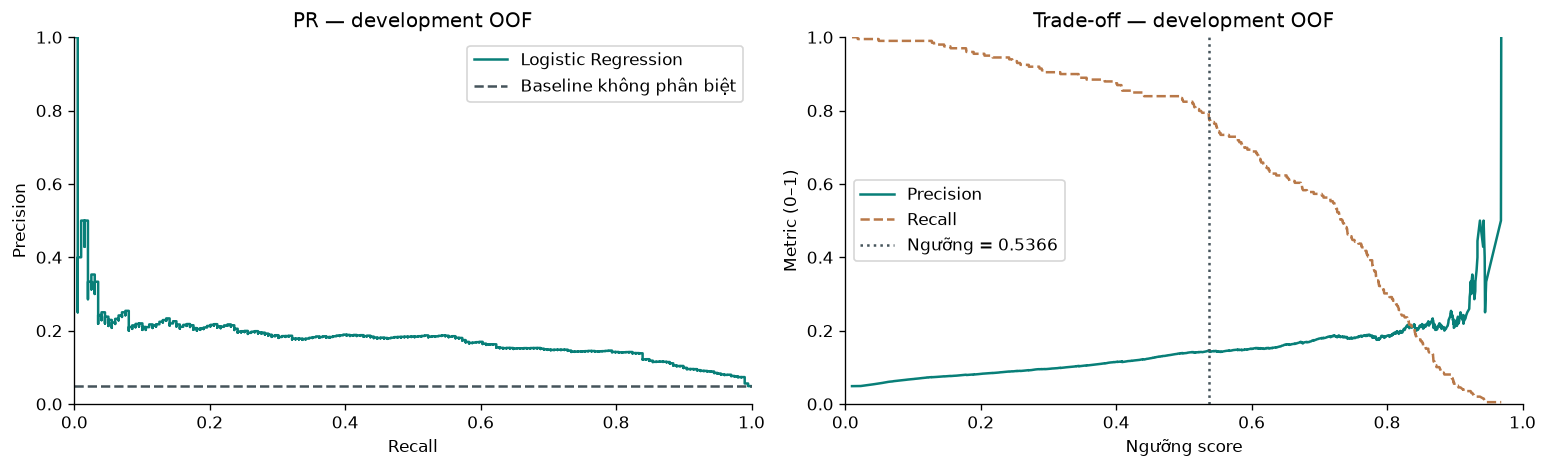

In [15]:
oof_precision, oof_recall, oof_thresholds = precision_recall_curve(y_dev, selected_oof)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].step(oof_recall, oof_precision, where='post', color=COLORS['model'], label=selected['family'])
axes[0].axhline(y_dev.mean(), color='#45545b', linestyle='--', label='Baseline không phân biệt')
axes[0].set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1), title='PR — development OOF')
axes[0].legend()
axes[1].plot(oof_thresholds, oof_precision[:-1], label='Precision', color=COLORS['model'])
axes[1].plot(oof_thresholds, oof_recall[:-1], label='Recall', color=COLORS['positive'], linestyle='--')
axes[1].axvline(selected_threshold, color='#45545b', linestyle=':', label=f'Ngưỡng = {selected_threshold:.4f}')
axes[1].set(xlabel='Ngưỡng score', ylabel='Metric (0–1)', xlim=(0, 1), ylim=(0, 1), title='Trade-off — development OOF')
axes[1].legend()
plt.tight_layout(); plt.show()

### 4.5. Hiệu chuẩn và tầm quan trọng đặc trưng
Reliability curve sử dụng 5 nhóm theo phân vị score OOF. Với 199 nhãn dương trên tập phát triển, thí nghiệm này không fit thêm bước hiệu chuẩn hậu nghiệm; mức độ hiệu chuẩn được báo cáo bằng đường reliability và Brier score.

Permutation importance đo mức giảm AP sau khi xáo từng đặc trưng trên validation fold. Mỗi mô hình được fit trên training fold, đánh giá qua 3 fold và 5 lần xáo. Các đặc trưng tương quan có thể che lấp hoặc chia sẻ tầm quan trọng. Độ lệch chuẩn giữa các lần lặp không phải khoảng tin cậy.

**English:** Calibration and global importance: assess OOF reliability/Brier and development-fold permutation importance; do not interpret score as validated future risk.

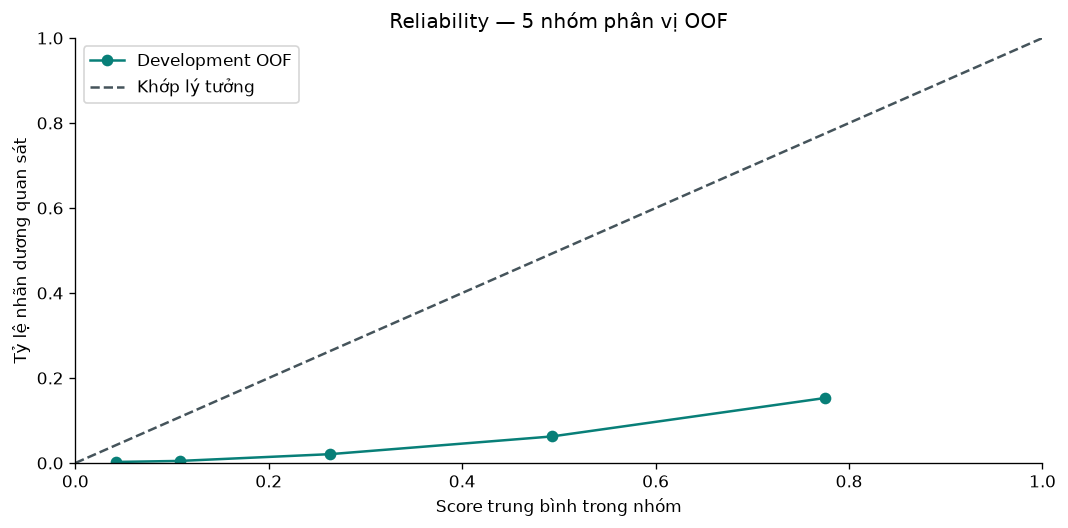

,Mean score,Observed rate
0,0.0417,0.0024
1,0.1082,0.0049
2,0.2633,0.0208
3,0.4926,0.0624
4,0.7748,0.1528


OOF Brier: 0.17235742729084524


In [16]:
observed_rate, predicted_mean = calibration_curve(y_dev, selected_oof, n_bins=5, strategy='quantile')
fig, ax = plt.subplots()
ax.plot(predicted_mean, observed_rate, marker='o', color=COLORS['model'], label='Development OOF')
ax.plot([0,1], [0,1], linestyle='--', color='#45545b', label='Khớp lý tưởng')
ax.set(xlabel='Score trung bình trong nhóm', ylabel='Tỷ lệ nhãn dương quan sát',
       xlim=(0,1), ylim=(0,1), title='Reliability — 5 nhóm phân vị OOF')
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({'Mean score': predicted_mean, 'Observed rate': observed_rate}))
print('OOF Brier:', selected['brier'])

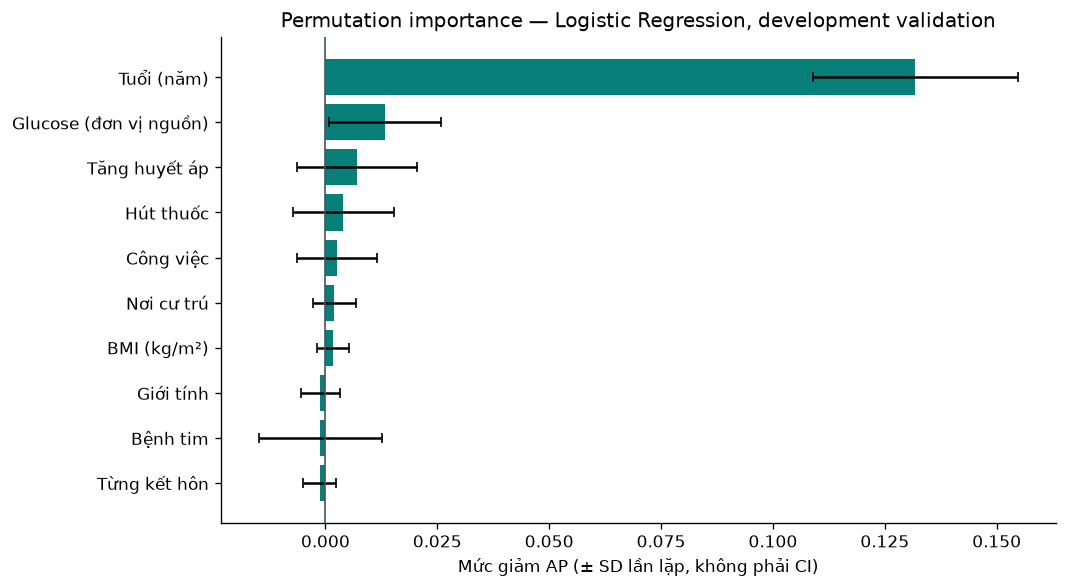

,feature,mean_ap_decrease,repeat_sd
0,age,0.1318,0.0229
3,avg_glucose_level,0.0133,0.0124
1,hypertension,0.0070,0.0134
9,smoking_status,0.0040,0.0113
7,work_type,0.0026,0.0089
8,Residence_type,0.0020,0.0048
4,bmi,0.0017,0.0036
5,gender,-0.0011,0.0044
2,heart_disease,-0.0012,0.0137
6,ever_married,-0.0013,0.0036


In [17]:
importance_runs = []
for train_rows, validation_rows in folds:
    fold_model = clone(unfitted_pipelines[winner_index]).fit(
        X_dev.iloc[train_rows], y_dev.iloc[train_rows])
    result = permutation_importance(fold_model, X_dev.iloc[validation_rows],
        y_dev.iloc[validation_rows], scoring='average_precision',
        n_repeats=5, random_state=SEED, n_jobs=1)
    importance_runs.append(result.importances)
importance_values = np.concatenate(importance_runs, axis=1)
importance_table = pd.DataFrame({'feature': FEATURES,
    'mean_ap_decrease': importance_values.mean(axis=1),
    'repeat_sd': importance_values.std(axis=1)}).sort_values('mean_ap_decrease')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_table.feature.map(LABELS), importance_table.mean_ap_decrease,
        xerr=importance_table.repeat_sd, color=COLORS['model'], capsize=3)
ax.axvline(0, color='#45545b', linewidth=1)
ax.set(xlabel='Mức giảm AP (± SD lần lặp, không phải CI)',
       title=f'Permutation importance — {selected["family"]}, development validation')
plt.tight_layout(); plt.show()
display(importance_table.sort_values('mean_ap_decrease', ascending=False).round(4))

## 5. Đánh giá trên holdout
Sau khi cố định mô hình, preprocessing và ngưỡng, pipeline được fit lại trên tập phát triển. Dự đoán holdout được tính một lần và tái sử dụng cho bảng cùng biểu đồ. Baseline luôn dự đoán nhãn 0.

Notebook tái lập thiết kế thí nghiệm và cách chia dữ liệu đã dùng trong StrokeLens; đây không phải tập kiểm định mới độc lập với thí nghiệm trước.

**English:** Final holdout: compute metrics only after locking selection; report confusion counts and uncertainty, not only accuracy.

In [18]:
final_pipeline = clone(unfitted_pipelines[winner_index]).fit(X_dev, y_dev)
X_holdout = df_raw.iloc[holdout_index][FEATURES]
y_holdout = df_raw.iloc[holdout_index]['stroke']
holdout_scores = final_pipeline.predict_proba(X_holdout)[:, 1]
holdout_metrics = evaluate_scores(y_holdout, holdout_scores, selected_threshold)
baseline_pipeline = make_pipeline(DummyClassifier(strategy='most_frequent')).fit(X_dev, y_dev)
baseline_scores = baseline_pipeline.predict_proba(X_holdout)[:, 1]
baseline_metrics = evaluate_scores(y_holdout, baseline_scores, .5)
metric_names = ['ap', 'recall', 'precision', 'f1', 'roc_auc', 'accuracy', 'brier']
scorecard = pd.DataFrame({
    'Development OOF — selection': {k:selected[k] for k in metric_names},
    'Final holdout — selected': {k:holdout_metrics[k] for k in metric_names},
    'Final holdout — majority': {k:baseline_metrics[k] for k in metric_names},
})
display(scorecard.round(4))
matrix = np.asarray(holdout_metrics['confusion'])
tn, fp, fn, tp = matrix.ravel()
recall_ci = wilson_interval(int(tp), int(tp + fn))
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}; n={matrix.sum()}, positives={tp+fn}')
print(f'Recall Wilson 95%: [{recall_ci[0]:.3f}, {recall_ci[1]:.3f}]')

,Development OOF — selection,Final holdout — selected,Final holdout — majority
ap,0.1793,0.1715,0.0489
recall,0.7940,0.8200,0.0000
precision,0.1456,0.1470,0.0000
f1,0.2461,0.2492,0.0000
roc_auc,0.8309,0.8534,0.5000
accuracy,0.7632,0.7583,0.9511
brier,0.1724,0.1737,0.0489


TN=734, FP=238, FN=9, TP=41; n=1022, positives=50
Recall Wilson 95%: [0.692, 0.902]


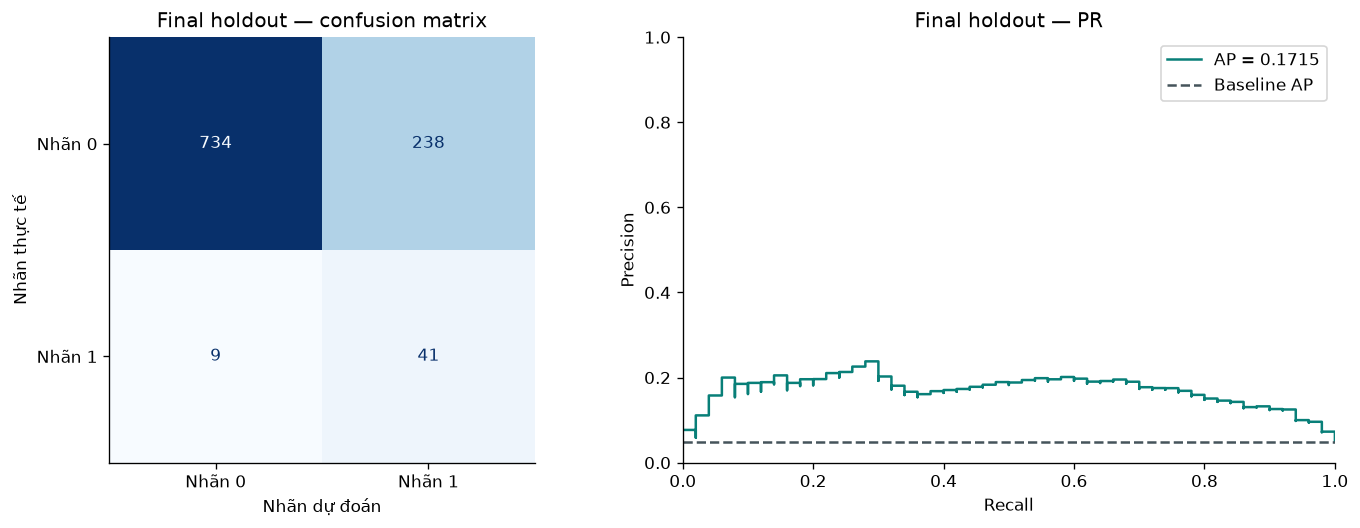

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=['Nhãn 0', 'Nhãn 1']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set(title='Final holdout — confusion matrix', xlabel='Nhãn dự đoán', ylabel='Nhãn thực tế')
test_precision, test_recall, _ = precision_recall_curve(y_holdout, holdout_scores)
axes[1].step(test_recall, test_precision, where='post', color=COLORS['model'],
             label=f'AP = {holdout_metrics["ap"]:.4f}')
axes[1].axhline(y_holdout.mean(), color='#45545b', linestyle='--', label='Baseline AP')
axes[1].set(title='Final holdout — PR', xlabel='Recall', ylabel='Precision',
            xlim=(0,1), ylim=(0,1))
axes[1].legend(); plt.tight_layout(); plt.show()

In [20]:
display(Markdown(f"""
**Diễn giải từ lần chạy này:** recall {holdout_metrics['recall']:.1%} tương ứng
{tp}/{tp+fn} nhãn dương được nhận diện; {fn} nhãn dương bị bỏ sót.
Precision {holdout_metrics['precision']:.1%} nghĩa là {tp}/{tp+fp} dự đoán dương là đúng;
có **{fp} dương tính giả**. Không chỉ báo cáo recall/accuracy.

Brier selected {holdout_metrics['brier']:.4f} so với majority {baseline_metrics['brier']:.4f}.
{'Score hiệu chuẩn kém hơn baseline; không được diễn giải như xác suất cá nhân.' if holdout_metrics['brier'] > baseline_metrics['brier'] else 'Brier tốt hơn baseline trong split này, chưa đủ để xác thực xác suất cá nhân.'}
Wilson recall 95% [{recall_ci[0]:.1%}, {recall_ci[1]:.1%}] mô tả bất định của
{tp+fn} positives trong split này; không bao gồm selection bias hoặc model-selection uncertainty.
"""))


**Diễn giải từ lần chạy này:** recall 82.0% tương ứng
41/50 nhãn dương được nhận diện; 9 nhãn dương bị bỏ sót.
Precision 14.7% nghĩa là 41/279 dự đoán dương là đúng;
có **238 dương tính giả**. Không chỉ báo cáo recall/accuracy.

Brier selected 0.1737 so với majority 0.0489.
Score hiệu chuẩn kém hơn baseline; không được diễn giải như xác suất cá nhân.
Wilson recall 95% [69.2%, 90.2%] mô tả bất định của
50 positives trong split này; không bao gồm selection bias hoặc model-selection uncertainty.


## 6. Mô phỏng đầu vào và giải thích mô hình
Hai hồ sơ giả định được dùng để quan sát phản hồi của mô hình. Danh mục đầu vào dùng giá trị chữ; numeric giữ đơn vị nguồn và được kiểm tra trong khoảng quan sát. BMI thiếu được xử lý bởi imputer đã fit.

Với Logistic Regression, đóng góp của mỗi đặc trưng bằng giá trị sau biến đổi nhân với hệ số, gộp theo đặc trưng gốc. Tổng đóng góp cộng intercept bằng log-odds; sigmoid của log-odds bằng score. Đây là phân rã của mô hình, không phải tác động nhân quả. Nếu mô hình được chọn phi tuyến, chỉ báo cáo tầm quan trọng toàn cục.

**English:** Fictional-profile demonstrations explain the fitted model and do not provide medical advice or causal effects.

In [21]:
def predict_profile(profile):
    if set(profile) != set(FEATURES):
        raise ValueError('Hồ sơ cần đúng 10 feature; không truyền id/stroke.')
    for column, choices in CATEGORIES.items():
        if profile[column] not in choices:
            raise ValueError(f'{column}: category không hợp lệ.')
    for column in NUMERIC:
        value = profile[column]
        if column == 'bmi' and value is None:
            continue
        if isinstance(value, (bool, str)) or value is None or not np.isfinite(value):
            raise ValueError(f'{column}: cần số hữu hạn.')
        if column in ['hypertension', 'heart_disease'] and value not in [0, 1]:
            raise ValueError(f'{column}: cần 0/1.')
        if column in SOURCE_RANGES:
            low, high = SOURCE_RANGES[column]
            if not low <= value <= high:
                raise ValueError(f'{column}: ngoài observed range [{low}, {high}].')
    frame = pd.DataFrame([{**profile, 'bmi': np.nan if profile['bmi'] is None else profile['bmi']}], columns=FEATURES)
    score = float(final_pipeline.predict_proba(frame)[0, 1])
    return frame, {'score': score, 'threshold': selected_threshold,
                   'above_threshold': score >= selected_threshold,
                   'bmi_imputed': profile['bmi'] is None}

profile_a = {'age': 25, 'hypertension': 0, 'heart_disease': 0,
    'avg_glucose_level': 85, 'bmi': 22, 'gender': 'Female', 'ever_married': 'No',
    'work_type': 'Private', 'Residence_type': 'Rural', 'smoking_status': 'never smoked'}
profile_b = {**profile_a, 'age': 75, 'hypertension': 1, 'heart_disease': 1,
    'avg_glucose_level': 200, 'bmi': 35, 'gender': 'Male', 'ever_married': 'Yes',
    'Residence_type': 'Urban', 'smoking_status': 'formerly smoked'}
frame_a, prediction_a = predict_profile(profile_a)
frame_b, prediction_b = predict_profile(profile_b)
display(pd.DataFrame([prediction_a, prediction_b], index=['Giả định A', 'Giả định B']))
print('Điểm số nghiên cứu; không chẩn đoán hoặc xác suất đột quỵ tương lai.')

,score,threshold,above_threshold,bmi_imputed
Giả định A,0.0583,0.5366,False,False
Giả định B,0.9214,0.5366,True,False


Điểm số nghiên cứu; không chẩn đoán hoặc xác suất đột quỵ tương lai.


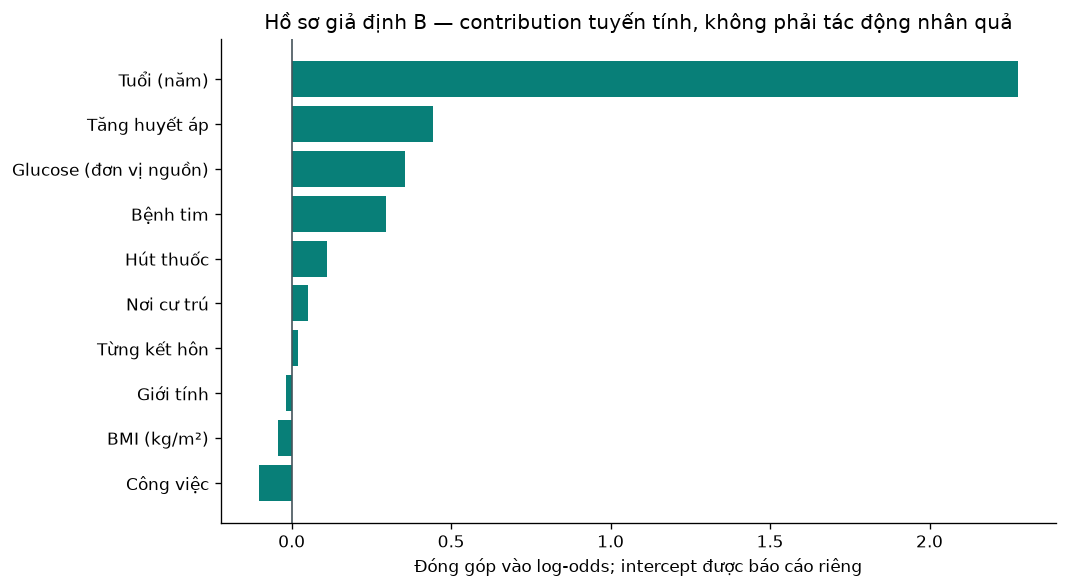

Intercept=-0.9281; log-odds=2.4614; score=0.9214


In [22]:
def local_linear_terms(pipeline, frame):
    estimator = pipeline.named_steps['model']
    if not isinstance(estimator, LogisticRegression):
        return None
    preprocess = pipeline.named_steps['preprocess']
    transformed = preprocess.transform(frame)[0]
    terms = transformed * estimator.coef_[0]
    grouped = {feature: float(terms[i]) for i, feature in enumerate(NUMERIC)}
    offset = len(NUMERIC)
    encoder = preprocess.named_transformers_['category']
    for feature, categories in zip(CATEGORIES, encoder.categories_):
        size = len(categories)
        grouped[feature] = float(terms[offset:offset+size].sum())
        offset += size
    intercept = float(estimator.intercept_[0])
    log_odds = intercept + sum(grouped.values())
    return pd.Series(grouped), intercept, log_odds

local_result = local_linear_terms(final_pipeline, frame_b)
if local_result is None:
    print('Winner phi tuyến: chỉ có global importance; không tạo attribution cá nhân giả.')
else:
    contributions, intercept, log_odds = local_result
    assert np.isclose(1 / (1 + np.exp(-log_odds)), prediction_b['score'])
    ordered = contributions.sort_values()
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(ordered.index.map(LABELS), ordered.values, color=COLORS['model'])
    ax.axvline(0, color='#45545b', linewidth=1)
    ax.set(xlabel='Đóng góp vào log-odds; intercept được báo cáo riêng',
           title='Hồ sơ giả định B — contribution tuyến tính, không phải tác động nhân quả')
    plt.tight_layout(); plt.show()
    print(f'Intercept={intercept:.4f}; log-odds={log_odds:.4f}; score={prediction_b["score"]:.4f}')

## 7. Kiểm tra và lưu kết quả
Đối chiếu fitted median và thống kê scaling với tập phát triển; kiểm tra mẫu số, khóa định danh, đầu vào không hợp lệ và khả năng xử lý BMI thiếu. Pipeline hoàn chỉnh được lưu rồi đọc lại để so sánh inference. Kết quả được xuất vào thư mục riêng `outputs/upgraded_notebook/`.

**English:** Validate source, split, fitted preprocessing and serialization; save generated outputs separately from raw data.

In [23]:
numeric_transform = final_pipeline.named_steps['preprocess'].named_transformers_['numeric']
np.testing.assert_allclose(numeric_transform.named_steps['impute'].statistics_, X_dev[NUMERIC].median())
np.testing.assert_allclose(numeric_transform.named_steps['scale'].mean_,
    X_dev[NUMERIC].fillna(X_dev[NUMERIC].median()).mean())
assert numeric_transform.named_steps['scale'].n_samples_seen_ == len(X_dev)
assert matrix.sum() == len(y_holdout)
assert int(matrix[1].sum()) == int(y_holdout.sum())
assert len(df_raw) == 5110 and df_raw['id'].is_unique
assert 'id' not in FEATURES and 'stroke' not in FEATURES
_, missing_prediction = predict_profile({**profile_a, 'bmi': None})
assert np.isfinite(missing_prediction['score'])
for corrupted in [{'age': 188}, {'avg_glucose_level': 9297}, {'gender': 'invalid'}]:
    try:
        predict_profile({**profile_a, **corrupted})
    except ValueError:
        pass
    else:
        raise AssertionError('Simulator phải từ chối dữ liệu bị lỗi.')

project_root = PROJECT_ROOT
OUTPUT_DIR = project_root / 'outputs/upgraded_notebook'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / 'pipeline_upgraded.joblib'
joblib.dump({'pipeline': final_pipeline, 'threshold': selected_threshold,
             'features': FEATURES, 'family': selected['family'], 'data_sha256': source_hash}, model_path)
reloaded = joblib.load(model_path)
np.testing.assert_allclose(reloaded['pipeline'].predict_proba(frame_a),
                           final_pipeline.predict_proba(frame_a))
comparison.drop(columns='confusion').to_csv(OUTPUT_DIR / 'cv_comparison.csv', index=False, encoding='utf-8-sig')
report = {'selected': selected, 'holdout': holdout_metrics, 'baseline': baseline_metrics,
    'recall_ci': list(recall_ci), 'data_sha256': source_hash,
    'development_n': len(development_index), 'holdout_n': len(holdout_index),
    'environment': ENVIRONMENT, 'constraint_met': constraint_met}
(OUTPUT_DIR / 'metrics_upgraded.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('PASS: source, split, fit statistics, inference, validation và serialization.')
print('Đầu ra riêng: outputs/upgraded_notebook/')

PASS: source, split, fit statistics, inference, validation và serialization.
Đầu ra riêng: outputs/upgraded_notebook/


## 8. Kết luận và hướng phát triển
Logistic Regression với trọng số lớp cân bằng đạt AP 0,1715, recall 82,0% và precision 14,7% trên holdout. Mô hình nhận diện 41 trong 50 nhãn dương nhưng tạo 238 dương tính giả. Vì vậy, recall cần được đánh giá cùng precision và số lượng từng loại lỗi.

Brier score 0,1737 cao hơn baseline 0,0489 cho thấy điểm số chưa phù hợp để diễn giải thành xác suất cá nhân. Kết quả chỉ phục vụ nghiên cứu giáo dục, chưa hỗ trợ quyết định chăm sóc sức khỏe.

### Giới hạn
Nguồn và cơ chế chọn mẫu chưa rõ, BMI thiếu khác nhau theo nhãn, yếu tố nhiễu chưa được kiểm soát, `Other` quá hiếm và đơn vị glucose chưa được xác nhận. Holdout chỉ có 50 nhãn dương và chưa có kiểm định ngoài mẫu. Dữ liệu không có timestamp để đánh giá thay đổi theo thời gian.

### Hướng phát triển
Phân tích sâu hơn missingness theo nhóm, đánh giá độ ổn định bằng resampling trên tập phát triển và kiểm chứng trên một nguồn dữ liệu độc lập. Mọi thay đổi mô hình hoặc hiệu chuẩn cần tập kiểm định phù hợp; không tiếp tục điều chỉnh dựa trên holdout đã báo cáo.

### Tài liệu tham khảo
- [Fedesoriano — Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset).
- [scikit-learn — Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn — Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html).
- [scikit-learn — Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).

**English:** Conclusions: educational use only. Discuss poor calibration, many false positives, lack of external validation and AI-assisted contribution honestly.